# CivicAI - 03 Model comparison

This notebook compares two baselines and three models that predict `resolved_within_7d` (1 = the request was closed within 7 days, 0 = it took longer).

1. Data and how models are judged
2. Why the cross-validation is time-aware
3. Baselines
4. Light tuning with cross-validation (training split only)
5. Validation results for every model
6. ROC curves, confusion matrices and feature importance
7. Best single model, and is stacking worth it?

**Rules followed here**

- Models are tuned with cross-validation on the **training split** and compared on the **validation split**. The **test split is not opened** in this notebook. It is scored once, in Phase 6.
- Every model is the same clean/encode pipeline from `src/features.py` with a classifier on the end, so all of them see exactly the same 12 features.
- `random_state=42` everywhere, so the numbers can be reproduced.

**Which class matters.** About 83% of requests are class 1 (resolved within 7 days). **Class 0 - not resolved within 7 days - is the one operations staff want to flag**, so its precision, recall and F1 are highlighted in the tables:

- *recall of class 0*: of the requests that really took longer than 7 days, what share did the model flag?
- *precision of class 0*: of the requests the model flagged, what share really took longer than 7 days?

**Main metrics.** Accuracy is misleading here, because always answering "within 7 days" is already right about 83% of the time. The main metrics are **macro F1** (the average of the F1 of class 0 and class 1, so both classes count equally) and **ROC-AUC** (how well the model ranks slow requests above fast ones, whatever cut-off is used).

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

sys.path.insert(0, "..")                  # so that "src" can be imported from the notebooks folder
from src import features as ft
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
MODEL_COLORS = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "XGBoost": AQUA}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})

X_train, y_train = tr.load_xy("train", "../data/processed")
X_val, y_val = tr.load_xy("val", "../data/processed")       # test.parquet is not read in this notebook
train_dates = X_train["created_date"]

print(f"Training split  : {len(X_train):,} rows, class 0 share {1 - y_train.mean():.1%}")
print(f"Validation split: {len(X_val):,} rows, class 0 share {1 - y_val.mean():.1%}")
print(f"Final features ({len(ft.FINAL_FEATURES)}): {ft.FINAL_FEATURES}")

Training split  : 139,206 rows, class 0 share 17.2%
Validation split: 29,830 rows, class 0 share 16.8%
Final features (12): ['complaint_type', 'descriptor', 'location_type', 'borough', 'incident_zip', 'open_data_channel_type', 'latitude', 'longitude', 'hour', 'weekday', 'month', 'is_weekend']


## 2. Why the cross-validation is time-aware

**Cross-validation** means: cut the training split into parts, train on some, score on the rest, and repeat, so that a setting is judged on several scores instead of one.

The usual way shuffles the rows at random. That would be wrong here, for the same reason the main split is by time: requests are filed over time, and the model will always be used on requests **newer** than the ones it learned from. With random folds a model would train on December requests and be scored on November ones. It could then pick up things about that period (a cold week, a backlog at one agency) that it could never know in real use, and its scores would look better than they really are.

`TimeSeriesSplit(n_splits=5)` keeps the order. The training split is cut into 6 blocks by date. Fold 1 trains on block 1 and validates on block 2; fold 2 trains on blocks 1-2 and validates on block 3; and so on. **Every fold trains on the past and validates on the next block**, which is what will happen in real use.

Two things to know when reading the results: the early folds train on little data, so their scores are lower and the standard deviation across folds is larger than with random folds; and the first block is never used for validation.

In [2]:
folds = []
for number, (train_index, validate_index) in enumerate(tr.time_folds().split(X_train), 1):
    folds.append({"fold": number,
                  "train_rows": len(train_index),
                  "train_from": train_dates.iloc[train_index[0]].date(), "train_to": train_dates.iloc[train_index[-1]].date(),
                  "validate_rows": len(validate_index),
                  "validate_from": train_dates.iloc[validate_index[0]].date(), "validate_to": train_dates.iloc[validate_index[-1]].date(),
                  "validate_class0_share": 1 - y_train.iloc[validate_index].mean()})
display(pd.DataFrame(folds).style.format({"train_rows": "{:,}", "validate_rows": "{:,}", "validate_class0_share": "{:.1%}"}).hide(axis="index"))

fold,train_rows,train_from,train_to,validate_rows,validate_from,validate_to,validate_class0_share
1,"23,201",2024-01-01,2024-05-08,"23,201",2024-05-08,2024-09-04,19.9%
2,"46,402",2024-01-01,2024-09-04,"23,201",2024-09-04,2024-12-27,16.7%
3,"69,603",2024-01-01,2024-12-27,"23,201",2024-12-27,2025-04-23,15.3%
4,"92,804",2024-01-01,2025-04-23,"23,201",2025-04-23,2025-08-14,17.3%
5,"116,005",2024-01-01,2025-08-14,"23,201",2025-08-14,2025-12-02,14.8%


## 3. Baselines

A model is only useful if it beats a simple rule. Two rules are used:

- **Majority class.** Always answer "resolved within 7 days". It never flags a slow request, so its recall for class 0 is zero.
- **Complaint type only.** For each complaint type, remember from the training split whether most of its requests were resolved within 7 days, and always give that answer. (Its score for ranking is the type's share resolved within 7 days.) A type that is not in the training rows gets the overall majority; in practice rare and new types are already grouped as `Other` by the cleaning step, so they share one answer.

The second baseline is the important one. Notebooks 01 and 02 showed that the complaint type carries most of the signal. This baseline measures exactly how far the complaint type alone gets, so the gap between it and the models is **what the models add** by also using the descriptor, location, channel and time.

In [3]:
baselines = tr.make_baselines()
cv_rows = {}
for name, model in baselines.items():
    cv_rows[name] = tr.cross_validate_model(model, X_train, y_train)
display(pd.DataFrame(cv_rows).T.style.format("{:.4f}"))

,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std
Baseline: majority class,0.4541,0.0053,0.5000,0.0000
Baseline: complaint type only,0.7989,0.0095,0.9384,0.0095


## 4. Light tuning with cross-validation

Each model has a few settings that change how it behaves. A small number of settings (6 to 8 per model) is tried, each one scored with the 5 time-ordered folds **on the training split only**. The setting with the highest mean **macro F1** across the folds is chosen (ROC-AUC breaks ties).

**How each model handles the 17% minority class**

- **Logistic Regression**: `class_weight="balanced"`. A mistake on a class 0 request counts about 5 times as much as a mistake on a class 1 request, so the model cannot ignore the rare class. Setting tried: `C`, the strength of regularisation (smaller `C` = simpler model). `max_iter=3000` so the solver has enough iterations to converge.
- **Random Forest**: `class_weight="balanced_subsample"`, the same idea worked out inside each tree's sample. Settings tried: `max_depth` and `min_samples_leaf`. The number of trees is fixed at 150 and the depth is capped at 40 so the saved file stays small enough for a small server.
- **XGBoost** (`tree_method="hist"`): `scale_pos_weight`. In XGBoost the "positive" class is class 1, our *common* class, so a value **below 1** makes class 1 count less. Two values are tried: the full balance (rows of class 0 / rows of class 1, about 0.21) and a milder half-way value (its square root, about 0.46). Other settings tried: tree depth, and more trees with a smaller learning rate.

In [4]:
settings = tr.settings_to_try(y_train)
print(f"scale_pos_weight values tried for XGBoost: full balance = {tr.class_ratio(y_train):.4f}, half-way = {np.sqrt(tr.class_ratio(y_train)):.4f}")

tuning_tables, best_settings = [], {}
for name, settings_list in settings.items():
    start = time.time()
    table = tr.tune(name, settings_list, X_train, y_train)
    tuning_tables.append(table)
    best_settings[name] = json.loads(table.loc[0, "settings"])
    cv_rows[name] = table.loc[0, ["cv_macro_f1_mean", "cv_macro_f1_std", "cv_roc_auc_mean", "cv_roc_auc_std"]].astype(float).to_dict()
    print(f"\n{name}: {len(settings_list)} settings x 5 folds, {time.time() - start:.0f} s. Best first:")
    with pd.option_context("display.max_colwidth", None):
        display(table.drop(columns="model").style.format({c: "{:.4f}" for c in table.columns if c.startswith("cv_") and c != "cv_seconds"})
                .format({"cv_seconds": "{:.0f}"}).set_properties(subset=["settings"], **{"text-align": "left"}))

tuning = pd.concat(tuning_tables, ignore_index=True)
tuning.to_csv("../reports/tuning_results.csv", index=False)
Path("../reports/best_settings.json").write_text(json.dumps(best_settings, indent=2), encoding="utf-8")
print("\nBest settings:")
for name, chosen in best_settings.items():
    print(f"  {name}: {chosen}")
print("Saved ../reports/tuning_results.csv and ../reports/best_settings.json")

scale_pos_weight values tried for XGBoost: full balance = 0.2076, half-way = 0.4556



Logistic Regression: 6 settings x 5 folds, 212 s. Best first:


,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""C"": 0.3}",0.802406,0.008454,0.943968,0.009074,20
1,"{""C"": 3.0}",0.802348,0.008157,0.944222,0.008733,59
2,"{""C"": 1.0}",0.802161,0.008277,0.944238,0.008794,36
3,"{""C"": 0.1}",0.800624,0.008059,0.943172,0.009629,33
4,"{""C"": 0.03}",0.796684,0.007764,0.940409,0.011108,33
5,"{""C"": 0.01}",0.783032,0.011962,0.934865,0.013296,31



Random Forest: 6 settings x 5 folds, 376 s. Best first:


,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""n_estimators"": 150, ""max_depth"": 40, ""min_samples_leaf"": 5}",0.794336,0.007697,0.942600,0.008759,59
1,"{""n_estimators"": 150, ""max_depth"": 40, ""min_samples_leaf"": 10}",0.786489,0.007591,0.940587,0.009634,68
2,"{""n_estimators"": 150, ""max_depth"": 40, ""min_samples_leaf"": 20}",0.775471,0.007631,0.938049,0.010427,53
3,"{""n_estimators"": 150, ""max_depth"": 30, ""min_samples_leaf"": 5}",0.775087,0.005950,0.940442,0.008537,67
4,"{""n_estimators"": 150, ""max_depth"": 30, ""min_samples_leaf"": 10}",0.771340,0.006224,0.938609,0.008961,53
5,"{""n_estimators"": 150, ""max_depth"": 20, ""min_samples_leaf"": 5}",0.744840,0.009548,0.935771,0.008825,75



XGBoost: 8 settings x 5 folds, 373 s. Best first:


,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""n_estimators"": 600, ""learning_rate"": 0.05, ""max_depth"": 8, ""scale_pos_weight"": 0.4556}",0.823166,0.012726,0.945828,0.009336,69
1,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 8, ""scale_pos_weight"": 0.4556}",0.822917,0.012979,0.945815,0.009420,31
2,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 6, ""scale_pos_weight"": 0.4556}",0.822614,0.011480,0.945689,0.008999,31
3,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 4, ""scale_pos_weight"": 0.4556}",0.821044,0.011987,0.944669,0.008400,49
4,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 8, ""scale_pos_weight"": 0.2076}",0.803154,0.012003,0.945873,0.009367,48
5,"{""n_estimators"": 600, ""learning_rate"": 0.05, ""max_depth"": 8, ""scale_pos_weight"": 0.2076}",0.802918,0.011624,0.945813,0.009321,67
6,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 6, ""scale_pos_weight"": 0.2076}",0.799833,0.011453,0.945662,0.009234,38
7,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 4, ""scale_pos_weight"": 0.2076}",0.786932,0.010348,0.944206,0.008573,40



Best settings:
  Logistic Regression: {'C': 0.3}
  Random Forest: {'n_estimators': 150, 'max_depth': 40, 'min_samples_leaf': 5}
  XGBoost: {'n_estimators': 600, 'learning_rate': 0.05, 'max_depth': 8, 'scale_pos_weight': 0.4556}
Saved ../reports/tuning_results.csv and ../reports/best_settings.json


**Cross-validation summary** (training split, 5 time-ordered folds): the two baselines and each model at its best setting.

In [5]:
cv_summary = pd.DataFrame(cv_rows).T
cv_summary["macro F1 (mean +/- std)"] = [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_summary["cv_macro_f1_mean"], cv_summary["cv_macro_f1_std"])]
cv_summary["ROC-AUC (mean +/- std)"] = [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_summary["cv_roc_auc_mean"], cv_summary["cv_roc_auc_std"])]
display(cv_summary[["macro F1 (mean +/- std)", "ROC-AUC (mean +/- std)"]])

,macro F1 (mean +/- std),ROC-AUC (mean +/- std)
Baseline: majority class,0.4541 +/- 0.0053,0.5000 +/- 0.0000
Baseline: complaint type only,0.7989 +/- 0.0095,0.9384 +/- 0.0095
Logistic Regression,0.8024 +/- 0.0085,0.9440 +/- 0.0091
Random Forest,0.7943 +/- 0.0077,0.9426 +/- 0.0088
XGBoost,0.8232 +/- 0.0127,0.9458 +/- 0.0093


## 5. Validation results

Each tuned model is now fitted once on the **full training split** and scored on the **validation split**, which none of the tuning above has seen. The same is done for the two baselines.

Also recorded, because the model has to run on a small EC2 server:

- **training time** on this laptop,
- **saved file size** with `joblib` (the whole pipeline, cleaning and encoding included),
- **time to predict one request** (the median of 20 calls, starting from the raw request fields).

In [6]:
one_request = X_val.iloc[[0]]
fitted, probabilities, rows = {}, {}, []

candidates = dict(baselines)
candidates.update({name: tr.make_model(name, best_settings[name]) for name in best_settings})
for name, model in candidates.items():
    train_seconds = tr.fit_timed(model, X_train, y_train)
    metrics, probabilities[name] = tr.evaluate(model, X_val, y_val)
    fitted[name] = model
    rows.append({"model": name, **metrics, **cv_rows[name],
                 "train_seconds": train_seconds, "file_mb": tr.saved_size_mb(model),
                 "predict_one_ms": tr.predict_one_ms(model, one_request),
                 "settings": json.dumps(best_settings.get(name, {}))})

comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv("../reports/model_comparison.csv")
print("Saved ../reports/model_comparison.csv")

iterations = fitted["Logistic Regression"]["model"].n_iter_[0]
print(f"Logistic Regression converged in {iterations} iterations (limit 3000).")

Saved ../reports/model_comparison.csv
Logistic Regression converged in 105 iterations (limit 3000).


In [7]:
CLASS0 = ["precision_0", "recall_0", "f1_0"]
main_columns = ["accuracy"] + CLASS0 + ["precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc"]
print("Validation split. Class 0 (not resolved within 7 days) is highlighted.")
display(comparison[main_columns].style.format("{:.4f}")
        .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black", "font-weight": "bold"})
        .highlight_max(subset=["macro_f1", "roc_auc"], props="text-decoration: underline; font-weight: bold"))

print("Confusion matrix counts (validation split)")
display(comparison[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]]
        .rename(columns={"actual0_pred0": "slow, flagged (correct)", "actual0_pred1": "slow, missed",
                         "actual1_pred0": "fast, flagged by mistake", "actual1_pred1": "fast, not flagged (correct)"})
        .style.format("{:,}"))

print("Cost of each model")
display(comparison[["train_seconds", "file_mb", "predict_one_ms"]].style.format({"train_seconds": "{:.1f}", "file_mb": "{:.2f}", "predict_one_ms": "{:.1f}"}))

Validation split. Class 0 (not resolved within 7 days) is highlighted.


,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1,roc_auc
model,,,,,,,,,
Baseline: majority class,0.8321,0.0000,0.0000,0.0000,0.8321,1.0000,0.9084,0.4542,0.5000
Baseline: complaint type only,0.8915,0.6866,0.6499,0.6678,0.9301,0.9402,0.9351,0.8014,0.9377
Logistic Regression,0.8791,0.5963,0.8658,0.7062,0.9702,0.8818,0.9239,0.8150,0.9414
Random Forest,0.8542,0.5398,0.8906,0.6721,0.9746,0.8468,0.9062,0.7892,0.9408
XGBoost,0.8994,0.6620,0.8189,0.7321,0.9616,0.9157,0.9381,0.8351,0.9433


Confusion matrix counts (validation split)


,"slow, flagged (correct)","slow, missed","fast, flagged by mistake","fast, not flagged (correct)"
model,,,,
Baseline: majority class,0,"5,007",0,"24,823"
Baseline: complaint type only,"3,254","1,753","1,485","23,338"
Logistic Regression,"4,335",672,"2,935","21,888"
Random Forest,"4,459",548,"3,802","21,021"
XGBoost,"4,100",907,"2,093","22,730"


Cost of each model


,train_seconds,file_mb,predict_one_ms
model,,,
Baseline: majority class,0.0,0.00,0.1
Baseline: complaint type only,9.8,0.02,44.6
Logistic Regression,13.7,0.03,48.7
Random Forest,28.7,17.98,92.5
XGBoost,15.0,1.81,58.7


**Reading the results (validation split, 29,830 requests of which 5,007 are class 0).**

- **Both baselines are beaten on ranking, but the complaint-type baseline is strong.** Knowing only the complaint type already gives macro F1 0.801 and ROC-AUC 0.938. This confirms what notebooks 01 and 02 showed: most of the signal is in what the request is about.
- **XGBoost is the best model** on macro F1 (0.835) and ROC-AUC (0.943), and it has the highest accuracy (0.899). Compared with the complaint-type baseline it adds 0.034 macro F1, and it flags 82% of slow requests instead of 65%.
- **Logistic Regression** is second (macro F1 0.815). It flags more slow requests than XGBoost (87%) but with more false alarms: about 6 in 10 of its flags are right, against about 2 in 3 for XGBoost.
- **Random Forest** flags the most slow requests (89%) but with the most false alarms (54% of its flags are right). Its macro F1 (0.789) is slightly **below** the complaint-type baseline, although it ranks requests better than the baseline (ROC-AUC 0.941 against 0.938). Its best setting was the deepest one allowed, so it would probably improve with deeper trees, at the cost of a larger file.
- **The class weights explain the pattern.** All three models were told to care more about the rare class 0, so all three flag far more slow requests than the baseline, and pay for it with more false alarms. XGBoost did best with the milder weighting (0.46), which is why it has fewer false alarms than the other two.
- **Cross-validation and validation agree.** The order of the models is the same in both (XGBoost, then Logistic Regression, then Random Forest), and the validation scores are within about one to two standard deviations of the cross-validation means.
- **Cost is not a constraint.** Every model trains in under a minute, the largest saved file is 18 MB (Random Forest), and one prediction takes under 0.1 seconds on this laptop, most of which is the cleaning step.

## 6. Charts

### ROC curves

For every possible cut-off, the ROC curve shows the share of fast requests correctly recognised (y axis) against the share of slow requests wrongly called fast (x axis). A curve closer to the top-left corner is better; the diagonal is a model that guesses. The area under the curve is the ROC-AUC.

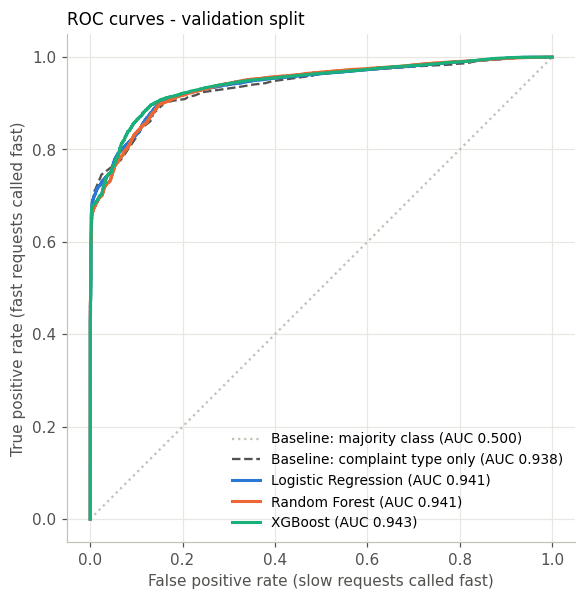

In [8]:
fig, ax = plt.subplots(figsize=(6.6, 6))
ax.plot([0, 1], [0, 1], color=GREY, linewidth=1.5, linestyle=":",
        label=f"Baseline: majority class (AUC {comparison.loc['Baseline: majority class', 'roc_auc']:.3f})")
fpr, tpr, _ = roc_curve(y_val, probabilities["Baseline: complaint type only"])
ax.plot(fpr, tpr, color=INK, linewidth=1.5, linestyle="--",
        label=f"Baseline: complaint type only (AUC {comparison.loc['Baseline: complaint type only', 'roc_auc']:.3f})")
for name, color in MODEL_COLORS.items():
    fpr, tpr, _ = roc_curve(y_val, probabilities[name])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC {comparison.loc[name, 'roc_auc']:.3f})")
ax.set_xlabel("False positive rate (slow requests called fast)")
ax.set_ylabel("True positive rate (fast requests called fast)")
ax.set_title("ROC curves - validation split", loc="left", fontsize=11)
ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.savefig(FIG_DIR / "05_roc_curves.png")
plt.show()

### Confusion matrices

Each matrix counts the validation requests by what really happened (rows) and what the model predicted (columns). The percentages are shares of each row, so the top-left cell is the **recall of class 0**: the share of slow requests the model flagged.

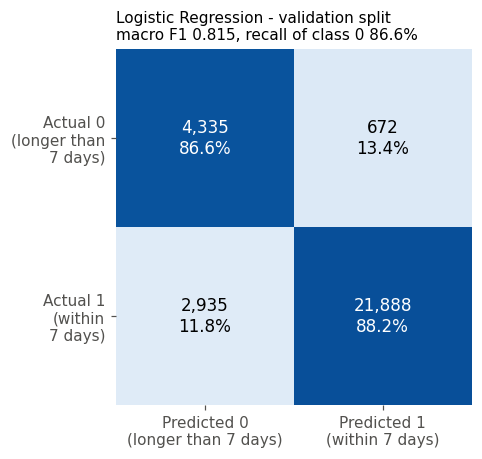

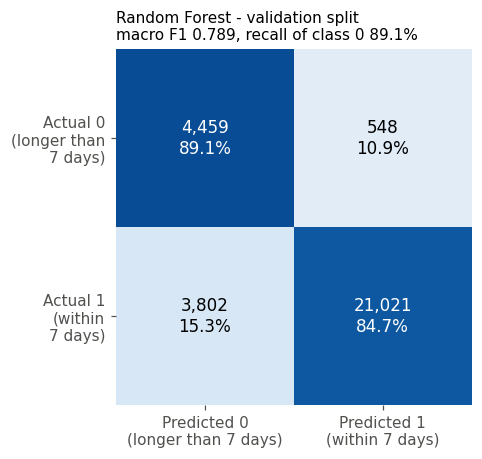

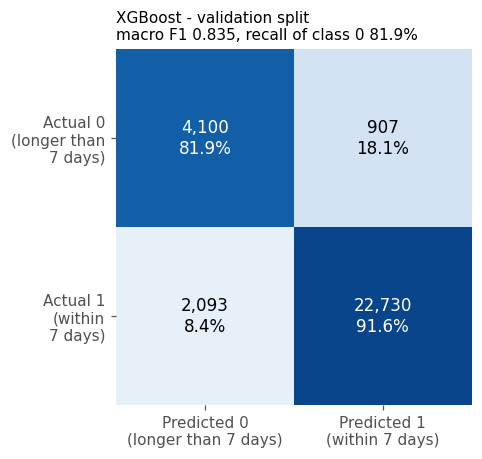

In [9]:
def plot_confusion(name, filename):
    row = comparison.loc[name]
    counts = np.array([[row["actual0_pred0"], row["actual0_pred1"]], [row["actual1_pred0"], row["actual1_pred1"]]], dtype=float)
    shares = counts / counts.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(counts[i, j]):,}\n{shares[i, j]:.1%}", ha="center", va="center", fontsize=11,
                    color="white" if shares[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1], ["Predicted 0\n(longer than 7 days)", "Predicted 1\n(within 7 days)"])
    ax.set_yticks([0, 1], ["Actual 0\n(longer than\n7 days)", "Actual 1\n(within\n7 days)"])
    ax.set_title(f"{name} - validation split\nmacro F1 {row['macro_f1']:.3f}, recall of class 0 {row['recall_0']:.1%}",
                 loc="left", fontsize=10)
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    fig.savefig(FIG_DIR / filename)
    plt.show()

plot_confusion("Logistic Regression", "05_confusion_logistic_regression.png")
plot_confusion("Random Forest", "05_confusion_random_forest.png")
plot_confusion("XGBoost", "05_confusion_xgboost.png")

### Feature importance of the best tree model

The tree model with the higher validation macro F1 is used. Its importance is reported per encoded column (one per category), so the columns are **added back up to the original 12 features**. For Random Forest the measure is the average reduction in impurity; for XGBoost it is the gain of its splits. Both come from the training data and tend to favour features with many categories, so read this as "what the model used", not as proof of what matters.

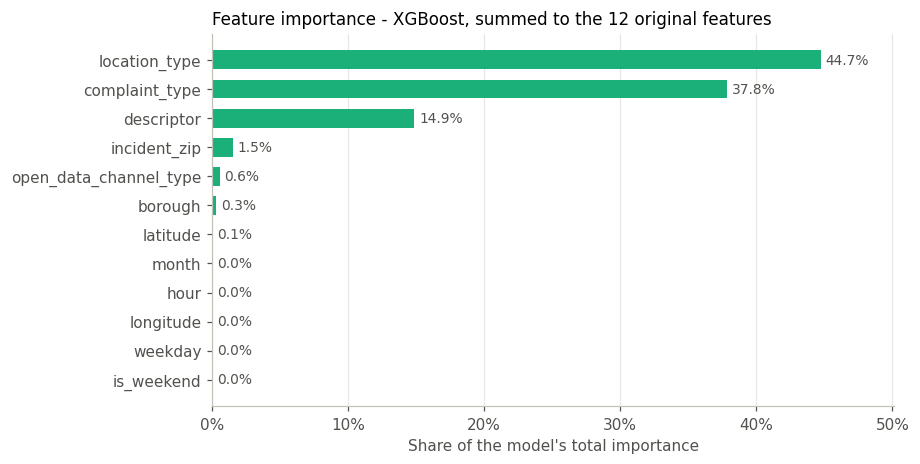

Best tree model by validation macro F1: XGBoost


,importance_share
location_type,44.7%
complaint_type,37.8%
descriptor,14.9%
incident_zip,1.5%
open_data_channel_type,0.6%
borough,0.3%
latitude,0.1%
month,0.0%
hour,0.0%
longitude,0.0%


In [10]:
best_tree = comparison.loc[["Random Forest", "XGBoost"], "macro_f1"].idxmax()
importance = tr.importance_by_feature(fitted[best_tree])
importance = importance / importance.sum()
assert set(importance.index) == set(ft.FINAL_FEATURES)

plot = importance.sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
bars = ax.barh(plot.index, plot.values, color=MODEL_COLORS[best_tree], height=0.65)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in plot.values], color=INK, fontsize=9, padding=3)
ax.set_xlim(0, plot.max() * 1.12)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Share of the model's total importance")
ax.set_title(f"Feature importance - {best_tree}, summed to the 12 original features", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "05_feature_importance_best_tree.png")
plt.show()
print(f"Best tree model by validation macro F1: {best_tree}")
display(importance.rename("importance_share").to_frame().style.format("{:.1%}"))

## 7. Best single model, and is stacking worth it?

**Choosing the best model.** The models are ranked by **validation macro F1**, with ROC-AUC as a second opinion. Macro F1 is used because it gives the rare class 0 the same weight as the common class 1, and class 0 is the one that matters to operations staff.

**Is stacking worth it?** A stack (Phase 6) combines the three models. It can only help if the models make *different* mistakes. Three checks on the validation split:

- how strongly the models' predicted probabilities are correlated (1.00 = they say the same thing),
- how often two models give a different answer for the same request,
- how many requests *every* model gets wrong (no combination can fix those) against how many *at least one* model gets right.

In [11]:
models = list(MODEL_COLORS)
ranking = comparison.loc[models].sort_values(["macro_f1", "roc_auc"], ascending=False)
best_model = ranking.index[0]
print(f"Best single model by validation macro F1: {best_model} "
      f"(macro F1 {ranking.loc[best_model, 'macro_f1']:.4f}, ROC-AUC {ranking.loc[best_model, 'roc_auc']:.4f})")
print(f"Best single model by validation ROC-AUC : {comparison.loc[models, 'roc_auc'].idxmax()} "
      f"({comparison.loc[models, 'roc_auc'].max():.4f})")
numbers = ["macro_f1", "roc_auc", "recall_0"]
gain = ranking.loc[best_model, numbers] - comparison.loc["Baseline: complaint type only", numbers]
print(f"Gain of {best_model} over the complaint-type baseline: macro F1 {gain['macro_f1']:+.4f}, "
      f"ROC-AUC {gain['roc_auc']:+.4f}, recall of class 0 {gain['recall_0']:+.4f}")

proba = pd.DataFrame({name: probabilities[name] for name in models})
predicted = (proba >= 0.5).astype(int)
print("\nCorrelation of predicted probabilities")
display(proba.corr().style.format("{:.3f}"))

print("Share of validation requests where two models give a different answer")
disagree = pd.DataFrame({a: {b: (predicted[a] != predicted[b]).mean() for b in models} for a in models})
display(disagree.style.format("{:.1%}"))

correct = predicted.eq(y_val.to_numpy(), axis=0)
print(f"All three models correct     : {correct.all(axis=1).mean():.1%}")
print(f"All three models wrong       : {(~correct).all(axis=1).mean():.1%}")
print(f"Models disagree (1 or 2 right): {(correct.any(axis=1) & ~correct.all(axis=1)).mean():.1%}")
print(f"Best single model correct    : {correct[best_model].mean():.1%}")
print(f"At least one model correct   : {correct.any(axis=1).mean():.1%}  (an upper limit no real stack reaches)")

average = proba.mean(axis=1)
from sklearn.metrics import f1_score, roc_auc_score
print(f"\nSimple average of the three probabilities: macro F1 {f1_score(y_val, average >= 0.5, average='macro'):.4f}, "
      f"ROC-AUC {roc_auc_score(y_val, average):.4f}")

Best single model by validation macro F1: XGBoost (macro F1 0.8351, ROC-AUC 0.9433)
Best single model by validation ROC-AUC : XGBoost (0.9433)
Gain of XGBoost over the complaint-type baseline: macro F1 +0.0337, ROC-AUC +0.0055, recall of class 0 +0.1690

Correlation of predicted probabilities


,Logistic Regression,Random Forest,XGBoost
Logistic Regression,1.000,0.975,0.975
Random Forest,0.975,1.000,0.951
XGBoost,0.975,0.951,1.000


Share of validation requests where two models give a different answer


,Logistic Regression,Random Forest,XGBoost
Logistic Regression,0.0%,5.1%,4.0%
Random Forest,5.1%,0.0%,7.0%
XGBoost,4.0%,7.0%,0.0%


All three models correct     : 83.4%
All three models wrong       : 8.6%
Models disagree (1 or 2 right): 8.1%
Best single model correct    : 89.9%
At least one model correct   : 91.4%  (an upper limit no real stack reaches)

Simple average of the three probabilities: macro F1 0.8296, ROC-AUC 0.9433


**Best single model: XGBoost**, chosen by **validation macro F1 (0.835)**. It is also best on ROC-AUC (0.943) and on cross-validated macro F1 (0.823), so the choice does not depend on which of these is used. Its settings are 600 trees, learning rate 0.05, depth 8 and `scale_pos_weight` 0.4556.

**Are the models different enough to be worth stacking? Only a little.**

- Their predicted probabilities are very similar: the correlations are between 0.95 and 0.98.
- Any two models give a different answer for only 4% to 7% of requests.
- All three are wrong on the same 8.6% of requests, which no combination can fix. At least one model is right for 91.4% of requests, against 89.9% for XGBoost alone, so the room for improvement is at most 1.5 percentage points, and a real stack gets only part of that.
- A simple average of the three probabilities scores macro F1 0.830 and ROC-AUC 0.943, which is **no better than XGBoost alone**.

**What to expect in Phase 6.** The stacking classifier is a required part of the project and will be built and compared honestly. A stack learns how much to trust each model, which is smarter than a plain average, so it may match XGBoost or improve on it slightly. A large gain is not expected, because all three models learn mostly the same thing from the same 12 features. If the stack does not beat XGBoost, that is a valid result to report.

**The test split has not been used.** It is scored once, in Phase 6.